# 7. The screen against my lung-organoid signatures

The question this notebook is for: can host-factor perturbation signatures from
a Calu-3 CRISPRi screen help interpret the transcriptional programs I see in
infected human lung organoids, and point at pathways behind the organoid
response?

The organoid differential-expression tables are from my own alveolar-organoid
reanalysis. They are not public and are not in this repository; point `ALO_LFC`
at a copy to run this notebook.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from matplotlib.lines import Line2D
from scipy import stats

import methods as M
from methods import TABLES, load_cells, bh_fdr, style
from methods import AQUA, NEUTRAL, GRID, INK, INK2

## The organoid signatures

**Purpose.** Four contrasts from the organoid work: infection within one run,
infection under drug, the drug effect in infected cells, and the cross-run
infection contrast used in the paper. The depth-matched version of each column
is preferred where it exists.

In [2]:
ALO = os.environ.get(
    "ALO_LFC", "/mnt/project-files/alo_reanalysis/results/04_all_gene_lfc.tsv.gz")

SIGNATURES = {
    "organoid_infection_within_run": "W3_within_run3_24h_infDMSO_VHC_vs_zero",
    "organoid_infection_under_drug": "W4_within_run3_24h_RMC_VHC_vs_zero",
    "organoid_drug_in_infected": "P6_24h_RMC_vs_DMSO_inf(run3)",
    "organoid_infection_cross_run": "P4_24h_inf(run3)_vs_uninf(run1)_DMSO [paper]",
}

HOST_DEPTH = 5000      # bystander median host UMI is ~26,000

MIN_CELLS = 30

MIN_ABS_LFC = 0.5      # genes the organoid signature actually moves

MIN_GENES = 40

def load_signatures() -> pd.DataFrame:
    if not os.path.exists(ALO):
        raise SystemExit(
            f"organoid LFC table not found at {ALO}. These tables are not public; "
            "set ALO_LFC to your own copy to run this step."
        )
    raw = pd.read_csv(ALO, sep="\t", low_memory=False)
    kind = raw.iloc[0]                      # row 0 labels each column raw / ds
    body = raw.iloc[1:].set_index(raw.columns[0])
    out = {}
    for label, col in SIGNATURES.items():
        # the depth-matched column is the ".1" partner labelled "ds"
        cand = [c for c in body.columns if c == col or c == col + ".1"]
        ds = [c for c in cand if str(kind.get(c)) == "ds"]
        use = ds[0] if ds else cand[0]
        out[label] = pd.to_numeric(body[use], errors="coerce")
        print(f"  {label}: column '{use}' ({kind.get(use)}), "
              f"{int(out[label].notna().sum())} genes")
    return pd.DataFrame(out)

print("organoid signatures (depth-matched where available):")
sig = load_signatures()
rows = []
for label in sig.columns:
    s = sig[label].dropna()
    rows.append(dict(signature=label, source_column=SIGNATURES[label],
                     n_genes=len(s), n_strong=int((s.abs() >= MIN_ABS_LFC).sum()),
                     median_abs_lfc=float(s.abs().median())))
pd.DataFrame(rows).to_csv(TABLES / "07_signature_overview.tsv", sep="\t", index=False)
print(pd.DataFrame(rows).round(3).to_string(index=False))

organoid signatures (depth-matched where available):


  organoid_infection_within_run: column 'W3_within_run3_24h_infDMSO_VHC_vs_zero.1' (ds), 5804 genes
  organoid_infection_under_drug: column 'W4_within_run3_24h_RMC_VHC_vs_zero.1' (ds), 5519 genes
  organoid_drug_in_infected: column 'P6_24h_RMC_vs_DMSO_inf(run3).1' (ds), 5684 genes
  organoid_infection_cross_run: column 'P4_24h_inf(run3)_vs_uninf(run1)_DMSO [paper].1' (ds), 5775 genes
                    signature                                source_column  n_genes  n_strong  median_abs_lfc
organoid_infection_within_run       W3_within_run3_24h_infDMSO_VHC_vs_zero     5804       888           0.210
organoid_infection_under_drug           W4_within_run3_24h_RMC_VHC_vs_zero     5519      2155           0.378
    organoid_drug_in_infected                 P6_24h_RMC_vs_DMSO_inf(run3)     5684       576           0.176
 organoid_infection_cross_run P4_24h_inf(run3)_vs_uninf(run1)_DMSO [paper]     5775      2304           0.389


## Is the organoid target in this library?

**Purpose.** Before any claim about my own target, check whether the screen
actually perturbs it.

**What it means.** PIP4K2C is not in this library, so nothing here can validate
that target directly. The screen is used for the pathways around it instead,
and the lipid-kinase question stays a hypothesis.

In [3]:
targets = set()
for t in load_cells().obs.target.unique():
    if t not in ("NTC", "unassigned"):
        targets.update(t.split("+"))
print(f"library targets: {len(targets)}")
for g in ["PIP4K2C", "PIP4K2A", "PIP4K2B", "PIKFYVE", "VAC14", "FIG4", "SPNS1"]:
    print(f"  {g:9s} {'in the library' if g in targets else 'NOT in the library'}")

library targets: 181
  PIP4K2C   NOT in the library
  PIP4K2A   NOT in the library
  PIP4K2B   NOT in the library
  PIKFYVE   NOT in the library
  VAC14     in the library
  FIG4      NOT in the library
  SPNS1     in the library


## Calu-3 bystander profiles at matched depth

**Purpose.** Score each element's bystander cells against the controls. Cells are
downsampled to a common host-UMI count and the controls are taken
leave-one-out, so neither depth nor an element's own cells can inflate its
score.

In [4]:
# ------------------------------------------------- Calu-3, depth-matched
a = load_cells(assigned_only=True)
state = pd.read_csv(TABLES / "01_cell_state.tsv.gz", sep="\t").set_index("cell_barcode")
a.obs["state"] = state.reindex(a.obs_names)["state"].to_numpy()
h = a[:, (a.var.kind == "host").to_numpy()].copy()
keep = (np.asarray(h.X.sum(axis=1)).ravel() >= HOST_DEPTH) & \
       (a.obs.state == "uninfected").to_numpy()
h = h[keep].copy()
obs = a.obs[keep].copy()
print(f"\nbystander cells at >= {HOST_DEPTH} host UMI: {h.shape[0]} "
      f"({obs.element.nunique()} elements, {int(obs.is_ntc.sum())} control cells)")
sc.pp.downsample_counts(h, counts_per_cell=HOST_DEPTH, random_state=0)

X = h.X.tocsr()
genes = np.array(h.var_names)
is_ntc = obs.is_ntc.to_numpy()
ntc_idx = np.where(is_ntc)[0]
detected = np.asarray((X > 0).mean(axis=0)).ravel()
expressed = detected >= 0.10
print(f"genes detected in >=10% of bystanders: {int(expressed.sum())}")

def profile(idx, ref_idx):
    """log2 fold change of mean downsampled expression, element vs reference."""
    m = np.asarray(X[idx].mean(axis=0)).ravel()
    r = np.asarray(X[ref_idx].mean(axis=0)).ravel()
    return np.log2((m + 0.01) / (r + 0.01))

shared = {}
for label in sig.columns:
    s = sig[label]
    strong = s[(s.abs() >= MIN_ABS_LFC) & s.notna()]
    idx = np.where(np.isin(genes, strong.index) & expressed)[0]
    shared[label] = (idx, strong.reindex(genes[idx]).to_numpy())
    print(f"  {label}: {len(idx)} genes shared, expressed and moved in the organoids")


bystander cells at >= 5000 host UMI: 16948 (235 elements, 1461 control cells)


genes detected in >=10% of bystanders: 5326


  organoid_infection_within_run: 357 genes shared, expressed and moved in the organoids


  organoid_infection_under_drug: 1029 genes shared, expressed and moved in the organoids


  organoid_drug_in_infected: 217 genes shared, expressed and moved in the organoids


  organoid_infection_cross_run: 1045 genes shared, expressed and moved in the organoids


## Element against signature

**Purpose.** For every element, the rank correlation between its Calu-3 profile
and each organoid signature, over the genes the organoid contrast actually
moves.

In [5]:
rows = []
for element, sub in obs.groupby("element", observed=True):
    if len(sub) < MIN_CELLS:
        continue
    idx = np.where(obs.element.to_numpy() == element)[0]
    ref = np.setdiff1d(ntc_idx, idx)        # leave-one-out for the controls
    if len(ref) < 100:
        continue
    p = profile(idx, ref)
    row = dict(element=element, target=sub.target.iloc[0],
               is_ntc=bool(sub.is_ntc.iloc[0]), n_cells=int(len(sub)))
    for label, (gidx, slfc) in shared.items():
        if len(gidx) < MIN_GENES:
            continue
        rho = stats.spearmanr(p[gidx], slfc).statistic
        row[f"rho_{label}"] = float(rho)
    rows.append(row)
el = pd.DataFrame(rows)

## A null from the controls

**Purpose.** A correlation on its own means nothing without knowing what the
non-targeting elements give. Their spread is the null, and each targeting
element is tested against it.

**What it means.** 17 elements separate from the control band on the organoid
drug signature, and 15 of them are the interferon axis: KEAP1, IRF9+IRF3,
STAT2, SPNS1, TYK2, IFNAR1/2, GPR89A/B, STAT1, BRD2 — including all four of the
paper's novel ISG regulators. Knocking down interferon signalling in Calu-3
cells moves them the way the drug moves infected organoids, which makes the
interferon axis the pathway-level link between the two systems.

In [6]:
# ----------------------------------------- control-based null and testing
for label in sig.columns:
    col = f"rho_{label}"
    if col not in el:
        continue
    null = el.loc[el.is_ntc, col].dropna()
    mu, sd = float(null.mean()), float(null.std(ddof=1))
    el[f"z_{label}"] = (el[col] - mu) / sd
    el[f"p_{label}"] = 2 * stats.norm.sf(el[f"z_{label}"].abs())
    q = np.full(len(el), np.nan)
    m = (~el.is_ntc).to_numpy()
    q[m] = bh_fdr(el.loc[m, f"p_{label}"].to_numpy())
    el[f"q_{label}"] = q
    print(f"\n{label}: control correlations {mu:+.3f} +- {sd:.3f} "
          f"(n = {len(null)} non-targeting elements)")
    t = el[~el.is_ntc]
    hits = t[t[f"q_{label}"] < 0.1]
    print(f"  {len(hits)} of {len(t)} elements differ from the control band at q < 0.1")
    if len(hits):
        print("  most like the organoid signature:")
        print(hits.nlargest(6, col)[["target", "n_cells", col, f"q_{label}"]]
              .round(3).to_string(index=False))
        print("  most opposite:")
        print(hits.nsmallest(6, col)[["target", "n_cells", col, f"q_{label}"]]
              .round(3).to_string(index=False))
el.to_csv(TABLES / "07_element_signature.tsv", sep="\t", index=False)


organoid_infection_within_run: control correlations -0.011 +- 0.076 (n = 20 non-targeting elements)
  7 of 170 elements differ from the control band at q < 0.1
  most like the organoid signature:
      target  n_cells  rho_organoid_infection_within_run  q_organoid_infection_within_run
      ATP1A1       48                              0.222                            0.068
   IRF9+IRF3       75                             -0.232                            0.084
TMPRSS2+CTSL      173                             -0.234                            0.084
 STAT1+STAT2       82                             -0.245                            0.068
       STAT1       79                             -0.245                            0.068
  ACE2+FURIN      141                             -0.266                            0.063
  most opposite:
       target  n_cells  rho_organoid_infection_within_run  q_organoid_infection_within_run
GPR89A+GPR89B       93                             -0.273        

## The two axes, and the autophagy module

**Purpose.** Compare the infection axis with the drug axis, and look specifically
at the autophagy-endolysosomal elements, which is where the organoid hypothesis
sits.

**What it means.** The autophagy-endolysosomal elements show no match (best
q = 0.10). That is what you would expect if that mechanism acts
post-transcriptionally, and it is a reason not to force the connection.

In [7]:
# --------------------------------------------------------- the headline
inf_col = "rho_organoid_infection_within_run"
drug_col = "rho_organoid_drug_in_infected"
t = el[~el.is_ntc].copy()
if inf_col in t and drug_col in t:
    print(f"\nthe two organoid axes are correlated across elements at "
          f"r = {np.corrcoef(t[inf_col], t[drug_col])[0,1]:.3f} "
          "(a perturbation that mimics infection tends to oppose the drug)")
    t["mimics_infection"] = t[f"q_organoid_infection_within_run"] < 0.1
    top = pd.concat([t.nlargest(10, inf_col), t.nsmallest(10, inf_col)])
    top.to_csv(TABLES / "07_top_elements.tsv", sep="\t", index=False)

# autophagy-module elements specifically
MODULE = ["ATG14", "ATG9A", "BECN1", "RB1CC1", "UVRAG", "VMP1", "TMEM41B",
          "RAB7A", "VPS11", "VPS16", "VPS33A", "VPS39", "CCZ1", "CCZ1B",
          "FYCO1", "ATP6AP1", "ATP6V1A", "ATP6V1B2", "M6PR", "SPNS1",
          "TMEM106B", "MFSD12", "SIGMAR1", "VAC14"]
mod = el[el.target.isin(MODULE)]
if len(mod) and inf_col in mod:
    print("\nthe autophagy-endolysosomal module, against the organoid infection "
          "signature:")
    print(mod.sort_values(inf_col)[
        ["target", "n_cells", inf_col, f"q_organoid_infection_within_run"]
    ].round(3).to_string(index=False))


the two organoid axes are correlated across elements at r = -0.578 (a perturbation that mimics infection tends to oppose the drug)

the autophagy-endolysosomal module, against the organoid infection signature:
  target  n_cells  rho_organoid_infection_within_run  q_organoid_infection_within_run
   ATG14       96                             -0.216                            0.102
   SPNS1      122                             -0.214                            0.102
   VAC14      112                             -0.169                            0.301
 TMEM41B       58                             -0.136                            0.420
   ATG9A       59                             -0.133                            0.432
  VPS33A       34                             -0.104                            0.603
 SIGMAR1      111                             -0.102                            0.603
  RB1CC1       68                             -0.096                            0.642
   VAC14      3

## Figure: the screen against the organoid signatures

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


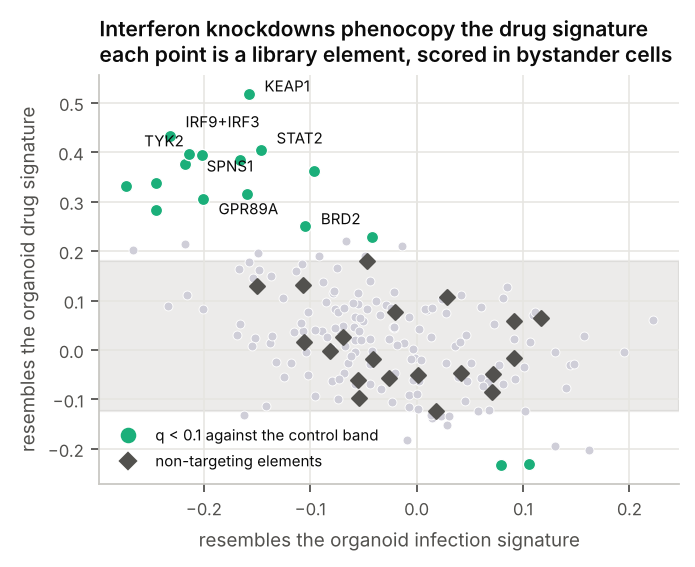

In [8]:
el = M.table("07_element_signature.tsv")

fig, ax = plt.subplots(figsize=(4.4, 3.6))
xcol = "rho_organoid_infection_within_run"
ycol = "rho_organoid_drug_in_infected"
t = el[~el.is_ntc]
n = el[el.is_ntc]
sig = t[t.q_organoid_drug_in_infected < 0.1]
ax.axhline(0, color=GRID, linewidth=0.8)
ax.axvline(0, color=GRID, linewidth=0.8)
ax.axhspan(n[ycol].min(), n[ycol].max(), color=NEUTRAL, alpha=0.25, zorder=0)
ax.scatter(t[xcol], t[ycol], s=16, color="#cfced8", edgecolor="white",
           linewidth=0.4, zorder=2)
ax.scatter(sig[xcol], sig[ycol], s=30, color=AQUA, edgecolor="white",
           linewidth=0.6, zorder=3)
ax.scatter(n[xcol], n[ycol], s=22, color=INK2, marker="D", zorder=4)
for lab, dx, dy in [("KEAP1", 7, 1), ("SPNS1", 8, -8), ("STAT2", 7, 3),
                    ("GPR89A", 7, -7), ("BRD2", 7, 1), ("IRF9+IRF3", 7, 4),
                    ("TYK2", -26, 4)]:
    r = sig[sig.target == lab]
    if len(r):
        ax.annotate(lab, (r[xcol].iloc[0], r[ycol].iloc[0]),
                    textcoords="offset points", xytext=(dx, dy),
                    fontsize=6.8, color=INK)
style(ax, grid_axis="both")
ax.set_xlabel("resembles the organoid infection signature")
ax.set_ylabel("resembles the organoid drug signature")
ax.set_title("Interferon knockdowns phenocopy the drug signature\n"
             "each point is a library element, scored in bystander cells",
             loc="left", fontsize=9.5)
ax.legend(handles=[
    Line2D([], [], marker="o", color=AQUA, linestyle="", markersize=6,
           label="q < 0.1 against the control band"),
    Line2D([], [], marker="D", color=INK2, linestyle="", markersize=5,
           label="non-targeting elements"),
], loc="lower left", fontsize=6.8)
fig.tight_layout()
fig.savefig(M.FIGURES / "organoid_signatures.png")
plt.show()